# Tutorial 1 — Excited states, couplings and symmetry

*Part 1 — Concepts · tutorial 1 of 9 · next: [02 Building a training set with SHARC](02_building_a_dataset.ipynb)*

This first tutorial explains the physics X-MACE is built on. There is no training
yet: we use small numerical examples and an untrained model to see **what** the
network predicts and **which symmetries are built into it**, so that you do not
have to learn them from data.

You will learn

1. which quantities surface-hopping dynamics (SHARC) needs, and what X-MACE predicts;
2. why non-adiabatic couplings (NACs) are learned as *smooth* NACs;
3. why the sign (phase) of every electronic state is arbitrary, and how training copes;
4. how spin multiplicities and their M_S components are organised (SHARC order);
5. which states spin–orbit coupling (SOC) can connect, and why singlets and quintets
   still mix;
6. how one *coupling vector* per pair of states gives the whole SOC block
   (Wigner–Eckart theorem);
7. what rotation equivariance means for energies, forces and couplings, and why
   couplings may be polar **or** axial vectors (planar molecules!).

Everything here runs in a few seconds on a laptop. Run the notebook from
`tutorials/xmace/`.

In [1]:
import warnings

warnings.filterwarnings("ignore")  # keep the output readable

import numpy as np
import matplotlib.pyplot as plt
import torch

import mace  # noqa: F401  (import first: it configures e3nn/torch)

np.set_printoptions(precision=4, suppress=True, linewidth=120)
torch.set_default_dtype(torch.float64)
plt.rcParams.update({"figure.dpi": 100, "figure.figsize": (6.4, 3.6)})

## 1. What surface hopping needs

In the Born–Oppenheimer picture the nuclei move on one potential energy surface
(PES) per electronic state. After light absorption a molecule is in an excited
state, and it can change state where surfaces come close (internal conversion,
between states of the same spin) or through spin–orbit coupling (intersystem
crossing, between states of different spin).

In **trajectory surface hopping** (SHARC, Newton-X, ...) classical nuclei move on
one surface at a time and may hop between surfaces. At every time step the dynamics
code needs, for every state *I* and pair of states *(I, J)*:

| quantity | symbol | used for |
|---|---|---|
| energies | $E_I$ | the surfaces |
| gradients / forces | $-\nabla E_I$ | moving the nuclei |
| non-adiabatic couplings | $\mathbf d_{IJ} = \langle \psi_I \lvert \nabla \psi_J \rangle$ | hops between states of the same spin |
| spin–orbit couplings | $\langle \psi_I \lvert \hat H_{SO} \rvert \psi_J \rangle$ | hops between states of different spin |
| (transition) dipoles | $\boldsymbol\mu_{IJ}$ | spectra, coupling to light fields |

A quantum-chemistry calculation of all of these takes minutes to hours per step.
An ML potential learns them from a few hundred to a few thousand reference
calculations and then predicts them in milliseconds.

**X-MACE** is MACE (an equivariant message-passing neural network) with outputs for
several states. One network predicts, for *S* spatial states:

| output | shape | |
|---|---|---|
| `energy` | `[n_graphs, S]` | total energy of every state (plus an optional ZBL core repulsion) |
| `forces` | `[n_atoms, S, 3]` | $-\nabla E_I$, by automatic differentiation |
| `nacs` | `[n_atoms, P, 3]` | smooth NACs, one vector per atom and coupled pair |
| `soc_vectors` | `[n_graphs, Q, 3]` | one SOC coupling vector per spin–orbit-coupled pair |
| `dipoles` | `[n_graphs, S + P, 3]` | permanent dipoles, then transition dipoles |

The rest of this notebook explains each of these.

## 2. Non-adiabatic couplings and smooth NACs

Take the simplest model of two coupled states: a 2×2 *diabatic* Hamiltonian along
one nuclear coordinate $x$,

$$ H(x) = \begin{pmatrix} x & c \\ c & -x \end{pmatrix}. $$

Its eigenvalues are the adiabatic energies $E_{1,2} = \mp\sqrt{x^2 + c^2}$, which
come closest at $x = 0$ (an avoided crossing). The NAC between the two adiabatic
states can be written with the Hellmann–Feynman-type formula

$$ d_{12} = \langle \psi_1 \lvert \partial_x \psi_2 \rangle
           = \frac{\langle \psi_1 \lvert \partial_x H \rvert \psi_2 \rangle}{E_2 - E_1}. $$

The numerator is smooth, but the denominator vanishes where the states meet: NACs
are sharply peaked near avoided crossings and **diverge at conical
intersections**. That is hard for any regression model. X-MACE therefore learns the
**smooth NAC** $\tilde{\mathbf d}_{IJ} = (E_J - E_I)\,\mathbf d_{IJ}$, which is just
the numerator, and divides by the predicted energy gap afterwards.

max |NAC| = 10.0, max |smooth NAC| = 1.00


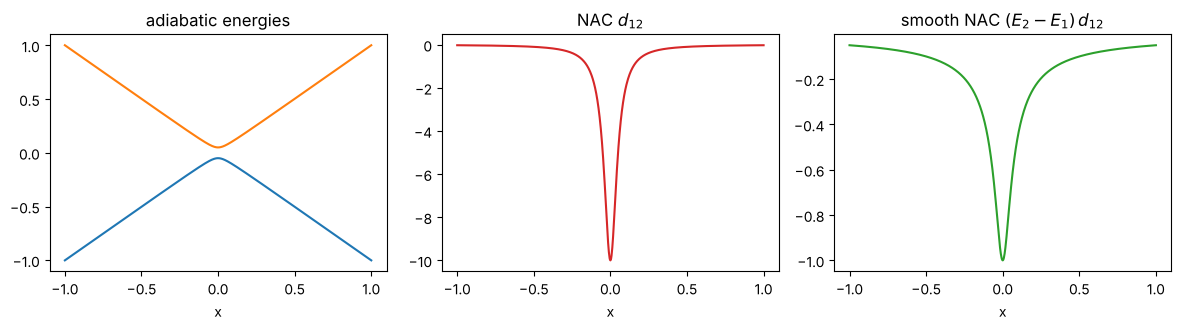

In [2]:
c = 0.05
x = np.linspace(-1, 1, 801)
energies, nacs, smooth = [], [], []
for xi in x:
    H = np.array([[xi, c], [c, -xi]])
    dH = np.array([[1.0, 0.0], [0.0, -1.0]])  # dH/dx
    e, v = np.linalg.eigh(H)
    v[:, 1] *= np.sign(v[0, 1]) or 1.0  # fix a phase convention, see section 3
    v[:, 0] *= np.sign(v[1, 0]) or 1.0
    numerator = v[:, 0] @ dH @ v[:, 1]
    energies.append(e)
    nacs.append(numerator / (e[1] - e[0]))
    smooth.append(numerator)
energies, nacs, smooth = map(np.array, (energies, nacs, smooth))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
axes[0].plot(x, energies)
axes[0].set(title="adiabatic energies", xlabel="x")
axes[1].plot(x, nacs, color="C3")
axes[1].set(title="NAC $d_{12}$", xlabel="x")
axes[2].plot(x, smooth, color="C2")
axes[2].set(title="smooth NAC $(E_2-E_1)\\,d_{12}$", xlabel="x")
plt.tight_layout()
print(f"max |NAC| = {np.abs(nacs).max():.1f}, max |smooth NAC| = {np.abs(smooth).max():.2f}")

The NAC reaches $1/(2c) = 10$ in a narrow peak, and it would be infinite for
$c = 0$. The smooth NAC is bounded and varies on the same length scale as the
energies, which is what a neural network learns well.

In the data you can provide either kind:

* `--nacs_format=raw` (or `auto` with a key name without "smooth"): X-MACE multiplies
  every NAC by the energy gap of its pair, using the reference energies of the same
  frame;
* `--nacs_format=smooth`: the NACs in the file are already smooth NACs.

The ASE and SHARC calculators return both: `smooth_nacs` as predicted and `nacs`
(smooth NACs divided by the predicted gap).

## 3. Arbitrary phases

An eigenvector is defined only up to its sign: if $\psi_I$ solves the electronic
Schrödinger equation, so does $-\psi_I$. Quantum-chemistry codes pick the sign more
or less at random at every geometry. Every coupling between two states changes
sign with either state:

$$ \mathbf d_{IJ} \to s_I s_J\, \mathbf d_{IJ}, \qquad
   \boldsymbol\mu_{IJ} \to s_I s_J\, \boldsymbol\mu_{IJ}, \qquad s_I = \pm 1. $$

Energies, forces and permanent dipoles do not depend on the signs. Let us redo the
calculation above with whatever sign `numpy` returns:

In [3]:
raw_signs = []
for xi in x[::40]:
    H = np.array([[xi, c], [c, -xi]])
    _, v = np.linalg.eigh(H)
    raw_signs.append(v[:, 0] @ np.diag([1.0, -1.0]) @ v[:, 1])
print("smooth NAC with numpy's own phases:", np.round(raw_signs, 3))

smooth NAC with numpy's own phases: [-0.05  -0.055 -0.062 -0.071 -0.083 -0.1   -0.124 -0.164 -0.243 -0.447 -1.    -0.447 -0.243 -0.164 -0.124 -0.1   -0.083
 -0.071 -0.062 -0.055 -0.05 ]


The magnitude is right but the sign jumps around. A model cannot (and should not)
learn such jumps. X-MACE therefore compares predictions with reference couplings
**using the better of the two signs**:

* NACs: one sign per frame and state pair, for all atoms together (the direction of
  the coupling vector matters, only its overall sign is free);
* transition dipoles: one sign per frame and pair;
* SOC coupling vectors: one sign per frame and pair.

This is done in the loss and in all error metrics, so **your training data does not
need consistent phases**. During dynamics the SHARC interface aligns the signs with
the previous time step, so the couplings SHARC sees change smoothly.

In [4]:
from mace.modules.excited import align_nacs

reference = torch.randn(4, 3, 3)  # 4 atoms, 3 pairs, xyz (one frame)
prediction = reference * torch.tensor([1.0, -1.0, 1.0]).view(1, 3, 1)  # pair 1 flipped
batch = torch.zeros(4, dtype=torch.long)  # all atoms belong to frame 0
aligned = align_nacs(reference, prediction, batch, 1)
print("error before alignment:", float((reference - prediction).abs().max()))
print("error after alignment: ", float((reference - aligned).abs().max()))

error before alignment: 3.4300822129136255
error after alignment:  0.0


## 4. Spin multiplicities and M_S components

Electronic states have a total spin *S* and multiplicity $2S + 1$: singlets
($S=0$), doublets ($S=\tfrac12$), triplets ($S=1$), quartets ($S=\tfrac32$), quintets
($S=2$), ... A state of spin *S* consists of $2S+1$ components with
$M_S = -S, \dots, S$. Without spin–orbit coupling they are exactly degenerate: same
energy, same gradient, same permanent dipole.

SHARC describes the states with a list of **spatial** states per multiplicity, e.g.
`states 2 0 2 0 1` = 2 singlets, 0 doublets, 2 triplets, 0 quartets, 1 quintet.
It works with the **M_S-resolved** states ("nmstates") in the order
*multiplicity → M_S → state*. X-MACE uses exactly this convention: train with
`--states="2 0 2 0 1"`, and the model predicts one energy per *spatial* state, in the
order S0, S1, T1, T2, Q1.

In [5]:
from mace.modules.spin_states import (
    describe_states,
    ms_resolved_map,
    n_mstates,
    same_multiplicity_pairs,
    spin_orbit_pairs,
    spatial_multiplicities,
)

states = [2, 0, 2, 0, 1]
names = {1: "S", 2: "D", 3: "T", 4: "Quart", 5: "Quint"}
mult = spatial_multiplicities(states)
labels, counter = [], {}
for m in mult:
    counter[m] = counter.get(m, 0) + 1
    labels.append(f"{names[m]}{counter[m] - (1 if m == 1 else 0)}")

print(describe_states(states), "->", sum(states), "spatial states,", n_mstates(states), "M_S states")
print(f"{'model index':>11}  {'state':>5}  SHARC indices (M_S)")
for k, components in enumerate(ms_resolved_map(states)):
    text = ", ".join(f"{index + 1} ({ms:+.0f})" for index, ms in components)
    print(f"{k:>11}  {labels[k]:>5}  {text}")

2 singlets, 2 triplets, 1 quintet -> 5 spatial states, 13 M_S states
model index  state  SHARC indices (M_S)
          0     S0  1 (+0)
          1     S1  2 (+0)
          2     T1  3 (-1), 5 (+0), 7 (+1)
          3     T2  4 (-1), 6 (+0), 8 (+1)
          4  Quint1  9 (-2), 10 (-1), 11 (+0), 12 (+1), 13 (+2)


SHARC numbers states from 1, so SHARC state 3 (the first triplet with
$M_S=-1$) is model state 2 (T1). The 13 × 13 SHARC Hamiltonian is built from 5
energies: X-MACE copies each energy, gradient and permanent dipole to all M_S
components, so they are **exactly degenerate by construction**.

## 5. Which states are coupled?

**NACs and transition dipoles** come from spin-free operators ($\nabla$, $\hat\mu$),
which do not change the spin: they only couple states of the **same multiplicity**,
and only components with the **same $M_S$**. X-MACE predicts one NAC and one
transition dipole per same-multiplicity pair of spatial states.

**Spin–orbit coupling** acts on the spin like a vector (a rank-1 tensor). By the
angular-momentum selection rules it couples spin *S* only to $S' = S, S \pm 1$, and
not $0 \to 0$; between $M_S$ components it needs $|M_S - M_S'| \le 1$.

In [6]:
print("NAC / transition-dipole pairs:", [(labels[i], labels[j]) for i, j in same_multiplicity_pairs(states)])
print("spin-orbit pairs:             ", [(labels[i], labels[j]) for i, j in spin_orbit_pairs(states)])

NAC / transition-dipole pairs: [('S0', 'S1'), ('T1', 'T2')]
spin-orbit pairs:              [('S0', 'T1'), ('S0', 'T2'), ('S1', 'T1'), ('S1', 'T2'), ('T1', 'T2'), ('T1', 'Quint1'), ('T2', 'Quint1')]


There is no S–S, S–Q5 or (with doublets) S–D coupling. Note the triplet–triplet and
triplet–quintet pairs: they are all spin–orbit coupled.

**Do singlets and quintets interact at all?** Not directly, but through the
triplets. SHARC diagonalises the full Hamiltonian (energies + SOCs), so an S–T and a
T–Q coupling together mix singlet and quintet character in second order. A small
numerical experiment (energies in eV, random coupling vectors of ~50 meV; the
function `soc_matrix_from_vectors` is explained in the next section):

In [7]:
from mace.modules.spin_states import soc_matrix_from_vectors

rng = np.random.default_rng(0)
energies_spatial = np.array([0.0, 3.00, 2.95, 3.20, 3.05])  # S0 S1 T1 T2 Q1
pairs = spin_orbit_pairs(states)
vectors = 0.05 * rng.standard_normal((len(pairs), 3))

diagonal = np.zeros(n_mstates(states))
for k, components in enumerate(ms_resolved_map(states)):
    for index, _ in components:
        diagonal[index] = energies_spatial[k]
quintet = [index for index, _ in ms_resolved_map(states)[4]]


def quintet_weight_of_s1(vectors):
    h = np.diag(diagonal) + soc_matrix_from_vectors(vectors, states)
    assert np.allclose(h, h.conj().T)
    e, u = np.linalg.eigh(h)
    s1 = np.argmax(np.abs(u[1]) ** 2)  # eigenstate with most S1 character
    return np.sum(np.abs(u[quintet, s1]) ** 2)


no_tq = vectors.copy()
for p, (i, j) in enumerate(pairs):
    if labels[j].startswith("Quint"):
        no_tq[p] = 0.0
print(f"quintet weight in the S1-like state: {quintet_weight_of_s1(vectors):.2e}")
print(f"... with the T-Q couplings removed:  {quintet_weight_of_s1(no_tq):.2e}")

quintet weight in the S1-like state: 4.87e-02
... with the T-Q couplings removed:  0.00e+00


With the triplet–quintet couplings switched off, singlets and quintets no longer mix:
all of the mixing went through the triplets. A trajectory can therefore go
S → T → Q5 in SHARC even though the direct S–Q5 matrix element is zero.

## 6. One vector per pair: the Wigner–Eckart theorem

Between two spatial states $I$ (spin $S$) and $J$ (spin $S'$) there are
$(2S+1)(2S'+1)$ SOC matrix elements, e.g. 15 for a triplet and a quintet. They are
not independent. The Wigner–Eckart theorem says that all of them follow from three
numbers (a *reduced* matrix element per Cartesian direction) times Clebsch–Gordan
coefficients. For real spatial wavefunctions the reduced matrix element is purely
imaginary, $i\,\mathbf a_{IJ}$ with a real vector $\mathbf a_{IJ}$:

$$ \langle I, M \lvert \hat H_{SO} \rvert J, M' \rangle
   = (-1)^q\, A_q\, c(S, S')\, \langle S' M'\, 1\, {-q} \mid S M \rangle,
   \qquad q = M' - M, $$

where $A_q$ are the spherical components of $\mathbf A = i\,\mathbf a_{IJ}$ and
$c(S,S) = \sqrt{S(S+1)}$, otherwise 1. For two states of the same spin this is just
$\mathbf a \cdot (i\hat{\mathbf S})$.

X-MACE (with `--soc_mode=spin_orbit`) predicts the vector $\mathbf a_{IJ}$ for every
spin–orbit-coupled pair and builds the complex SOC matrix with this formula
(`mace.modules.spin_states.soc_matrix_from_vectors`). So the predicted SOC matrix is
always Hermitian and has the right zeros. Let us look at its structure:

Hermitian: True


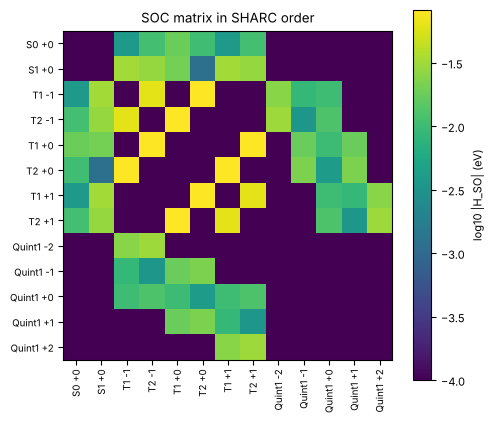

In [8]:
h_so = soc_matrix_from_vectors(vectors, states)
fig, ax = plt.subplots(figsize=(5, 4.4))
image = ax.imshow(np.log10(np.abs(h_so) + 1e-8), cmap="viridis", vmin=-4)
ticks = []
for k, components in enumerate(ms_resolved_map(states)):
    for index, ms in components:
        ticks.append((index, f"{labels[k]} {ms:+.0f}"))
ticks.sort()
ax.set_xticks([t[0] for t in ticks], [t[1] for t in ticks], rotation=90, fontsize=7)
ax.set_yticks([t[0] for t in ticks], [t[1] for t in ticks], fontsize=7)
fig.colorbar(image, label="log10 |H_SO| (eV)")
ax.set_title("SOC matrix in SHARC order")
plt.tight_layout()
print("Hermitian:", np.allclose(h_so, h_so.conj().T))

The dark squares are exact zeros: S–S, S–Q5, every block of a state with itself,
and all elements with $|\Delta M_S| > 1$. Now check the same-spin case against the
spin matrices directly:

In [9]:
from mace.modules.spin_states import spin_matrices

two_triplets = [0, 0, 2]
a = np.array([0.3, -0.2, 0.7])
h = soc_matrix_from_vectors(a[None, :], two_triplets)
rows = [index for index, _ in ms_resolved_map(two_triplets)[0]]
cols = [index for index, _ in ms_resolved_map(two_triplets)[1]]
expected = 1j * np.einsum("k,kab->ab", a, spin_matrices(1.0))
print("T1-T2 block equals a . iS:", np.allclose(h[np.ix_(rows, cols)], expected))

T1-T2 block equals a . iS: True


**Your SOC labels must have this form.** X-MACE fits the coupling vectors to every
SOC matrix in the training data by least squares and warns if a matrix deviates from
the Wigner–Eckart form, for example because the states are in another order, the
$M_S$ components use a different basis or phase convention, or only magnitudes
$|\langle I|H_{SO}|J\rangle|$ were stored. We checked SHARC's own reference outputs
from MOLCAS, MOLPRO and ADF: they fit to machine precision. Tutorial 2 shows an
example that does not.

In [10]:
from mace.modules.spin_states import soc_vectors_from_matrix

fitted, residual = soc_vectors_from_matrix(h_so, states)
print(f"fit of an exact SOC matrix:       residual = {residual:.1e}")
print("vectors recovered:", np.allclose(fitted, vectors))
_, residual = soc_vectors_from_matrix(np.abs(h_so).astype(complex), states)
print(f"fit of its magnitudes |H_SO|:     residual = {residual:.2f}")
mapping = {}  # triplet components in the order M_S = +1, 0, -1
for k, components in enumerate(ms_resolved_map(states)):
    targets = components[::-1] if mult[k] == 3 else components
    for (index, _), (target, _) in zip(components, targets):
        mapping[index] = target
p = [mapping[i] for i in range(n_mstates(states))]
_, residual = soc_vectors_from_matrix(h_so[np.ix_(p, p)], states)
print(f"fit with the triplet M_S reversed: residual = {residual:.2f}")

fit of an exact SOC matrix:       residual = 1.4e-16
vectors recovered: True
fit of its magnitudes |H_SO|:     residual = 0.89
fit with the triplet M_S reversed: residual = 0.33


## 7. Equivariance: what happens when the molecule rotates

If you rotate a molecule by a rotation matrix $R$:

* energies do not change (**invariant**);
* forces, NACs and dipoles rotate with it, $\mathbf v \to R\mathbf v$ (**equivariant**);
* the SOC coupling vectors rotate too, and the SOC matrix transforms as
  $H_{SO} \to U(R)\, H_{SO}\, U(R)^\dagger$, where $U(R)$ rotates the spins of every
  multiplet.

MACE builds these properties into the network, so they hold exactly for any
parameters — even for an untrained model. Let us build a small, untrained X-MACE
model with the Python API (Tutorial 3 trains one from the command line).

In [11]:
from e3nn import o3

from mace import data, modules, tools
from mace.tools import torch_geometric

z_table = tools.AtomicNumberTable([1, 6, 8])


def small_model(states, coupling_parity="both", seed=0):
    torch.manual_seed(seed)
    return modules.ExcitedMACE(
        r_max=4.0,
        num_bessel=8,
        num_polynomial_cutoff=5,
        max_ell=2,
        interaction_cls=modules.interaction_classes["RealAgnosticResidualInteractionBlock"],
        interaction_cls_first=modules.interaction_classes["RealAgnosticInteractionBlock"],
        num_interactions=2,
        num_elements=len(z_table),
        hidden_irreps=o3.Irreps("16x0e + 16x1o"),  # l=1 features: needed for vectors
        MLP_irreps=o3.Irreps("16x0e"),
        atomic_energies=np.zeros(len(z_table)),
        avg_num_neighbors=3.0,
        atomic_numbers=z_table.zs,
        correlation=2,
        gate=torch.nn.functional.silu,
        n_energies=sum(states),
        states=states,  # SHARC-style states per multiplicity
        compute_nacs=True,
        compute_socs=True,
        compute_dipoles=True,
        soc_mode="spin_orbit",  # Wigner-Eckart SOC vectors
        coupling_parity=coupling_parity,
    )


def predict(model, atoms):
    config = data.config_from_atoms(atoms)
    graph = data.AtomicData.from_config(config, z_table=z_table, cutoff=4.0)
    batch = next(iter(torch_geometric.dataloader.DataLoader([graph], batch_size=1)))
    out = model(batch.to_dict(), training=False, compute_force=True)
    return {k: v.detach().numpy() for k, v in out.items() if isinstance(v, torch.Tensor)}


import ase

formaldehyde = ase.Atoms(
    "COHH",
    positions=[[0.0, 0.0, 0.0], [0.0, 0.0, 1.21], [0.0, 0.94, -0.58], [0.0, -0.94, -0.58]],
)
formaldehyde.positions += 0.05 * np.random.default_rng(1).standard_normal((4, 3))  # distort

model = small_model([2, 0, 2])
print("NACs for pairs", model.nac_num, "| dipoles", model.dipole_num, "| SOC vectors", model.soc_vector_num)

NACs for pairs 2 | dipoles 6 | SOC vectors 5


In [12]:
from scipy.spatial.transform import Rotation

from mace.modules.spin_states import spin_rotation

R = Rotation.random(random_state=3).as_matrix()
rotated = formaldehyde.copy()
rotated.positions = formaldehyde.positions @ R.T
out, out_rot = predict(model, formaldehyde), predict(model, rotated)

print("energies invariant:   ", np.allclose(out_rot["energy"], out["energy"]))
print("forces rotate:        ", np.allclose(out_rot["forces"], out["forces"] @ R.T))
print("NACs rotate:          ", np.allclose(out_rot["nacs"], out["nacs"] @ R.T))
print("dipoles rotate:       ", np.allclose(out_rot["dipoles"], out["dipoles"] @ R.T))
H0 = soc_matrix_from_vectors(out["soc_vectors"][0], [2, 0, 2])
H1 = soc_matrix_from_vectors(out_rot["soc_vectors"][0], [2, 0, 2])
U = spin_rotation([2, 0, 2], R)
print("SOC matrix: H(Rx) = U H(x) U^dagger:", np.allclose(H1, U @ H0 @ U.conj().T))

energies invariant:    True
forces rotate:         True
NACs rotate:           True
dipoles rotate:        True
SOC matrix: H(Rx) = U H(x) U^dagger: True


### Polar or axial? Couplings in planar molecules

A *polar* vector (a dipole, a force) changes sign under inversion
$\mathbf r \to -\mathbf r$; an *axial* vector (an angular momentum, a magnetic
field) does not. Mirror reflections behave in the same way. What about couplings?
An improper operation can also flip the signs of the states, so a coupling between
two states may behave as either kind. This matters for **planar molecules**, where
every state is either symmetric or antisymmetric under reflection through the
molecular plane (A′ or A″):

* any polar vector that is a function of the positions lies **in** the plane;
* any axial vector is **perpendicular** to it;
* but the transition dipole of an $n\to\pi^*$ excitation (A′–A″) is
  **perpendicular** to the plane, and SOC vectors between states of the same
  reflection symmetry lie **in** it.

A model that makes NACs and transition dipoles purely polar and SOC vectors purely
axial cannot represent these couplings at all, however long you train. X-MACE
therefore gives every coupling vector a polar **and** an axial part by default
(`--coupling_parity=both`). It stays exactly equivariant under rotations.
`--coupling_parity=fixed` restores the strict parities. Permanent dipoles are always
polar.

In [13]:
planar = formaldehyde.copy()
planar.positions[:, 0] = 0.0  # molecule in the yz plane: its normal is x

for parity in ("fixed", "both"):
    out = predict(small_model([2, 0, 2], coupling_parity=parity), planar)
    transition = out["dipoles"][0, 4:]  # after the 4 permanent dipoles
    print(
        f"coupling_parity={parity:5s}: largest out-of-plane transition dipole "
        f"{np.abs(transition[:, 0]).max():.1e}, largest in-plane SOC vector component "
        f"{np.abs(out['soc_vectors'][0, :, 1:]).max():.1e}"
    )

coupling_parity=fixed: largest out-of-plane transition dipole 0.0e+00, largest in-plane SOC vector component 0.0e+00


coupling_parity=both : largest out-of-plane transition dipole 9.3e-04, largest in-plane SOC vector component 6.3e-03


With `fixed` parities both are exactly zero for a planar geometry; with `both` the
model can produce them. Tutorial 2 shows that this matters for real data: in SO2
(a triatomic is always planar), every SOC vector lies in the molecular plane.

Symmetry **axes** are a different matter: at a geometry with a rotation axis (e.g.
SO2 with two equal bonds), an equivariant model can only produce couplings along the
axis, while couplings between states of different symmetry species are perpendicular
to it. Such couplings come out as zero exactly at the symmetric geometry. Tutorial 5
shows what this looks like and how large the effect is.

## Summary

| built into X-MACE (exact) | learned from data |
|---|---|
| rotation invariance of energies, equivariance of forces, NACs, dipoles, SOC vectors | the energies, forces and couplings themselves |
| degenerate M_S components (energies, gradients, permanent dipoles) | |
| NACs / transition dipoles only within a multiplicity (and equal M_S) | |
| SOC selection rules, Hermiticity, Wigner–Eckart structure, spin rotation | |
| arbitrary phases (phase-free losses and metrics) | |

**Next:** [Tutorial 2](02_building_a_dataset.ipynb) builds a training set for SO2
with SHARC.